# Parados que cobran una prestación o un subsidio por desempleo

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "cobertura-prestaciones-desempleo"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Parados que cobran una prestación o un subsidio por desempleo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los parados registrados con empleo anterior"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La *tasa de cobertura bruta* del sistema de protección por desempleo que calcula el SEPE: los beneficiarios de prestaciones contributivas, subsidios, renta agraria y subsidio agrario y renta activa de inserción, en porcentaje de los parados registrados que han trabajado antes (más los beneficiarios del subsidio agrario, que no figuran como parados registrados). Es la media anual de las tasas mensuales.

**Por qué solo España.** El paro registrado y la definición de beneficiario son propios del sistema español; Eurostat no publica una tasa de cobertura comparable.

**Cómo se lee.** Un valor de 70 significa que, de cada 100 parados registrados con empleo anterior, unos 70 cobran alguna prestación o subsidio. Mide si la protección por desempleo llega a quienes han perdido el empleo, no la cuantía que cobran.

**Limitaciones.**
- **El denominador es el paro registrado**, no el paro de la Encuesta de Población Activa: muchos parados no se inscriben en las oficinas de empleo, sobre todo los que no tienen derecho a prestación.
- **Beneficiarios que no son parados registrados.** El numerador incluye a personas que no figuran como paradas registradas, como los trabajadores fijos discontinuos en los meses sin actividad o los del subsidio agrario; según el SEPE, en las provincias con muchos fijos discontinuos la tasa puede superar el 100 % en temporada baja.
- **Reformas.** La reforma laboral de 2022 extendió los contratos fijos discontinuos y el Real Decreto-ley 2/2024 reformó el subsidio por desempleo (más colectivos y compatibilidad con un empleo) desde noviembre de 2024: los cambios de la tasa reflejan también estos cambios de definición y de reglas.
- **Serie corta.** El SEPE publica en línea sus informes mensuales en Excel desde 2017.

## 2. Descarga

SEPE, informe mensual de prestaciones por desempleo de diciembre de cada año (`lib/sepe.py`): hoja TC-1.1a, tasa de cobertura del total de beneficiarios, fila del total nacional, columna «Media anual».

In [ ]:
import sys
from datetime import date
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import sepe
from lib.tipos import FuenteMeta

cob, fuentes_cob = sepe.get_cobertura(range(DESDE, date.today().year))

## 3. Transformación

Sin transformación: la tasa ya es la media anual que publica el SEPE.

In [ ]:
df = cob.assign(serie="espana")
assert df["valor"].between(20, 150).all(), "tasa fuera de rango"
fuentes = [FuenteMeta("espana", f.organismo, f.dataset_codigo, f.url, f.fecha_consulta) for f in fuentes_cob]
display(df.round(1))

,serie,periodo,valor
0,espana,2017,56.2
1,espana,2018,58.2
2,espana,2019,62.4
3,espana,2020,85.0
4,espana,2021,60.9
5,espana,2022,62.9
6,espana,2023,68.3
7,espana,2024,73.0
8,espana,2025,78.1


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


s = df.set_index("periodo")["valor"]
NOTAS = [
    "Tasa de cobertura bruta del sistema de protección por desempleo (SEPE, informe mensual de prestaciones, tabla "
    "TC-1.1a, media anual): beneficiarios de prestaciones contributivas, subsidios, renta agraria, subsidio agrario y "
    "renta activa de inserción entre los parados registrados con empleo anterior más los beneficiarios del subsidio "
    "agrario.",
    "El denominador es el paro registrado y no el de la EPA: muchos parados no se inscriben en las oficinas de empleo.",
    "El numerador incluye a personas que no figuran como paradas registradas, como los fijos discontinuos fuera de "
    "temporada o los beneficiarios del subsidio agrario; según el SEPE, en las provincias con muchos fijos "
    "discontinuos la tasa puede superar el 100 % en temporada baja.",
    "La reforma laboral de 2022 (contratos fijos discontinuos) y la reforma del subsidio por desempleo del Real "
    "Decreto-ley 2/2024, aplicada desde noviembre de 2024, cambian quién figura como parado y como beneficiario.",
    f"La serie empieza en {int(s.index.min())}, primer año con el informe mensual en Excel en la web del SEPE.",
]
for n in NOTAS:
    print("-", n)

- Tasa de cobertura bruta del sistema de protección por desempleo (SEPE, informe mensual de prestaciones, tabla TC-1.1a, media anual): beneficiarios de prestaciones contributivas, subsidios, renta agraria, subsidio agrario y renta activa de inserción entre los parados registrados con empleo anterior más los beneficiarios del subsidio agrario.
- El denominador es el paro registrado y no el de la EPA: muchos parados no se inscriben en las oficinas de empleo.
- El numerador incluye a personas que no figuran como paradas registradas, como los fijos discontinuos fuera de temporada o los beneficiarios del subsidio agrario; según el SEPE, en las provincias con muchos fijos discontinuos la tasa puede superar el 100 % en temporada baja.
- La reforma laboral de 2022 (contratos fijos discontinuos) y la reforma del subsidio por desempleo del Real Decreto-ley 2/2024, aplicada desde noviembre de 2024, cambian quién figura como parado y como beneficiario.
- La serie empieza en 2017, primer año con el

## 4. Visualización

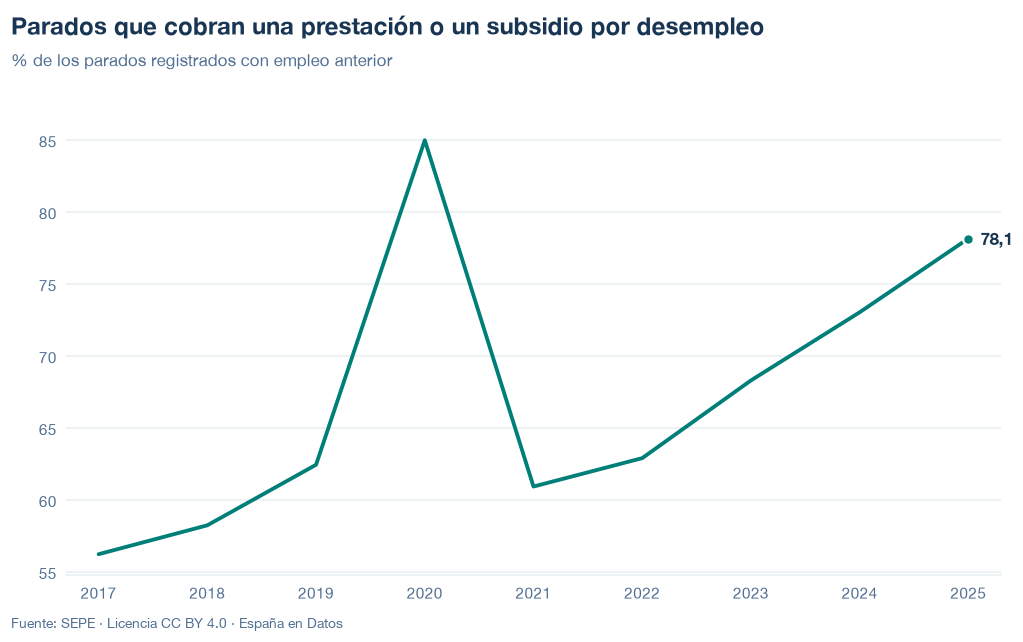

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/cobertura-prestaciones-desempleo.json y data/cobertura-prestaciones-desempleo.csv


## 6. Fuentes, notas y licencia

- SEPE, informe mensual de prestaciones por desempleo (diciembre de cada año), tabla TC-1.1a.

La fecha de consulta está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.